# 🌿 High Atlas Foundation — Tree Planting Impact Analysis
### Tensift Basin, Morocco | Remote Sensing & Hydrology Extension Notebook

---

This notebook contains all recommended analysis extensions for the HAF reforestation paper:

| # | Analysis | Key Library |
|---|----------|-------------|
| 1 | **Setup & Site Configuration** | `ee`, `geemap` |
| 2 | **NDVI Time Series (Core)** | `ee`, `pandas`, `matplotlib` |
| 3 | **CHIRPS Precipitation-Corrected NDVI** | `ee`, `sklearn` |
| 4 | **Mann-Kendall Trend Tests** | `pymannkendall` |
| 5 | **Enhanced Vegetation Index (EVI)** | `ee` |
| 6 | **Land Surface Temperature (LST)** | `ee` (Landsat thermal) |
| 7 | **Sentinel-1 SAR Soil Moisture Proxy** | `ee` |
| 8 | **GEDI Canopy Height** | `ee` |
| 9 | **Phenological Analysis (SOS/EOS)** | `ee`, `scipy` |
| 10 | **Groundwater + Precipitation Integration** | `pandas`, `scipy` |
| 11 | **ΔNDVI Spatial Change Map** | `ee`, `geemap` |
| 12 | **Publication-Quality Figure Generator** | `matplotlib`, `seaborn` |

> **Instructions:** Run cells top to bottom. Fill in your site coordinates and file paths in **Section 1**. Every section is self-contained after that.

---
## 📦 Section 0 — Install Dependencies

In [1]:
# Install all required packages
!pip install -q geemap pymannkendall earthengine-api scikit-learn scipy statsmodels matplotlib seaborn pandas numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 42.7 MB/s eta 0:00:00


In [3]:
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import pymannkendall as mk
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Authenticate and initialize Google Earth Engine
ee_project_name = 'thrive-care'                    # ← Replace with your GEE project ID
ee.Authenticate()
ee.Initialize(project=ee_project_name)

print("✅ All libraries loaded and GEE initialized.")

✅ All libraries loaded and GEE initialized.


---
## ⚙️ Section 1 — Site Configuration

**Fill in your HAF site coordinates and metadata here. Everything else in the notebook reads from this config.**

In [21]:
# ============================================================
#  SITE CONFIGURATION — Uses your farm_df and groundwater CSV
# ============================================================

# ── 1A. Load HAF Farm Sites from Excel ──────────────────────
farm_data_file_name = "/content/HAF_Planting_Sites_Registration_and_Monitoring_Marrakech.xlsx"
farm_df = pd.read_excel(farm_data_file_name)

farm_df = farm_df.rename(columns={
    "_Record a GPS point inside the planting site_latitude":  "lat",
    "_Record a GPS point inside the planting site_longitude": "lon",
    "_Record a GPS point inside the planting site_altitude":  "altitude",
    "_id":                    "farm_id",
    "The planting Season Year": "planting_year"
})

farm_df = farm_df.dropna(subset=["lat", "lon"])

print(f"✅ Loaded {len(farm_df)} farms with GPS coordinates.")

# Build HAF_SITES list from farm_df
# 'buffer_m' is the radius around each farm point used for satellite extraction
BUFFER_M = 500  # ← Adjust if your planting sites are larger or smaller

HAF_SITES = []
for _, row in farm_df.iterrows():
    HAF_SITES.append({
        "name":         str(row["farm_id"]),
        "lon":          float(row["lon"]),
        "lat":          float(row["lat"]),
        "buffer_m":     BUFFER_M,
        "planted_year": int(row["planting_year"]) if pd.notna(row.get("planting_year")) else 2020,
        "species":      str(row.get("species", "Unknown"))  # ← Add your species column name here if you have one
    })

# Build GEE FeatureCollection from farm_df
farm_features = []
for _, row in farm_df.iterrows():
    point   = ee.Geometry.Point([row["lon"], row["lat"]])
    feature = ee.Feature(point, {"Farm": str(row["farm_id"])})
    farm_features.append(feature)

farm_fc = ee.FeatureCollection(farm_features)
print(f"✅ GEE FeatureCollection created: {len(farm_features)} farm points.")

# ── 1B. Auto-generate Control Sites (offset from each farm) ─
# Each control is placed 0.01° (~1 km) west of the farm point.
# Adjust the offset direction/distance to match your landscape.
CONTROL_OFFSET_LON = -0.01   # degrees west  (~1 km)
CONTROL_OFFSET_LAT =  0.0    # no N/S offset

CONTROL_SITES = []
for site in HAF_SITES:
    CONTROL_SITES.append({
        "name":     f"Control_{site['name']}",
        "lon":      site["lon"] + CONTROL_OFFSET_LON,
        "lat":      site["lat"] + CONTROL_OFFSET_LAT,
        "buffer_m": site["buffer_m"]
    })

print(f"✅ {len(CONTROL_SITES)} control zones auto-generated (1 per farm, offset west).")
print("   ⚠️  Review control zone placement — adjust CONTROL_OFFSET_LON/LAT if needed.")

# ── 1C. Load Groundwater Data from your pre-built CSV ────────
# groundwater_timeseries.csv expected columns:
#   lat | lon | date | gw_level

# Option A: Upload directly in Colab
# from google.colab import files
# uploaded = files.upload()   # select groundwater_timeseries.csv
# gw_df = pd.read_csv("groundwater_timeseries.csv", parse_dates=["date"])

# Option B: Load from Google Drive (recommended)
# from google.colab import drive
# drive.mount('/content/drive')
# gw_df = pd.read_csv("/content/drive/MyDrive/HAF/groundwater_timeseries.csv", parse_dates=["date"])

# Option C: If already in Colab working directory
gw_df = pd.read_csv("groundwater_timeseries.csv", parse_dates=["date"])

# Validate expected columns are present
required_cols = {"lat", "lon", "date", "gw_level"}
missing = required_cols - set(gw_df.columns)
if missing:
    raise ValueError(f"❌ groundwater_timeseries.csv is missing columns: {missing}")

gw_df["gw_level"] = pd.to_numeric(gw_df["gw_level"], errors="coerce")
print(f"✅ Groundwater data loaded: {len(gw_df):,} records")
print(f"   Date range:    {gw_df['date'].min().date()} → {gw_df['date'].max().date()}")
print(f"   Lat range:     {gw_df['lat'].min():.3f} → {gw_df['lat'].max():.3f}")
print(f"   Lon range:     {gw_df['lon'].min():.3f} → {gw_df['lon'].max():.3f}")

# ── 1D. Build GW_WELLS list by matching wells to nearest farm ─
# For each unique well (location), finds the nearest HAF site.
from scipy.spatial import cKDTree

# Unique well locations
wells_unique = gw_df.groupby(["lat", "lon"]).mean().reset_index()
wells_unique["well_id"] = [f"Well_{i}" for i in range(1, len(wells_unique) + 1)]

# Build KD-tree
# KD-tree on farm coordinates for fast nearest-neighbour lookup
farm_coords = np.array([[s["lat"], s["lon"]] for s in HAF_SITES])
tree        = cKDTree(farm_coords)

GW_WELLS = []
for _, well_row in wells_unique.iterrows():
    dist, idx = tree.query([well_row["lat"], well_row["lon"]])
    dist_km   = dist * 111  # rough degrees → km conversion
    GW_WELLS.append({
        "well_id":      well_row["well_id"],
        "lon":          float(well_row["lon"]),
        "lat":          float(well_row["lat"]),
        "nearest_site": HAF_SITES[idx]["name"],
        "dist_km":      round(dist_km, 2)
    })

# add well_id, nearest_site and dist_km to gw_df
gw_df = gw_df.merge(wells_unique[["lat", "lon", "well_id"]], on=["lat", "lon"], how="left")
gw_df = gw_df.merge(pd.DataFrame(GW_WELLS)[["well_id", "nearest_site", "dist_km"]], on="well_id", how="left")

print(f"\n✅ {len(GW_WELLS)} groundwater wells matched to nearest HAF sites.")
print(f"   Distance range: {min(w['dist_km'] for w in GW_WELLS):.1f} – {max(w['dist_km'] for w in GW_WELLS):.1f} km")

# Flag wells that are very far from any farm (may not be hydrologically relevant)
far_wells = [w for w in GW_WELLS if w["dist_km"] > 10]
if far_wells:
    print(f"\n   ⚠️  {len(far_wells)} wells are >10 km from their nearest farm — review these:")
    for w in far_wells:
        print(f"      {w['well_id']} → {w['nearest_site']} ({w['dist_km']} km)")

# ── 1E. Study Period & Remote Sensing Settings ────────────────
START_DATE = '2019-01-01'
END_DATE   = '2024-12-31'

# Clip to actual groundwater data range if it's narrower
gw_start = gw_df["date"].min().strftime("%Y-%m-%d")
gw_end   = gw_df["date"].max().strftime("%Y-%m-%d")
if gw_start > START_DATE:
    print(f"\n   ℹ️  Groundwater data starts {gw_start} — consider setting START_DATE = '{gw_start}'")
if gw_end < END_DATE:
    print(f"   ℹ️  Groundwater data ends {gw_end} — consider setting END_DATE = '{gw_end}'")

# Growing season months (High Atlas: spring flush + autumn green-up)
GROWING_SEASON_MONTHS = [3, 4, 5, 9, 10, 11]  # March–May, Sept–Nov

# Cloud masking threshold (%)
CLOUD_THRESHOLD = 20

# ── Summary ──────────────────────────────────────────────────
print(f"\n{'='*55}")
print(f"  HAF farm sites:        {len(HAF_SITES)}")
print(f"  Control zones:         {len(CONTROL_SITES)}")
print(f"  Groundwater wells:     {len(GW_WELLS)}")
print(f"  Study period:          {START_DATE} → {END_DATE}")
print(f"{'='*55}")

✅ Loaded 233 farms with GPS coordinates.
✅ GEE FeatureCollection created: 233 farm points.
✅ 233 control zones auto-generated (1 per farm, offset west).
   ⚠️  Review control zone placement — adjust CONTROL_OFFSET_LON/LAT if needed.
✅ Groundwater data loaded: 2,593 records
   Date range:    2011-09-01 → 2026-04-01
   Lat range:     230821.000 → 299190.000
   Lon range:     299295.000 → 329220.000

✅ 25 groundwater wells matched to nearest HAF sites.
   Distance range: 42176663.1 – 48645313.8 km

   ⚠️  25 wells are >10 km from their nearest farm — review these:
      Well_1 → 326240822 (42664498.75 km)
      Well_2 → 326240822 (42176663.06 km)
      Well_3 → 326240822 (43279597.31 km)
      Well_4 → 326240822 (43569474.24 km)
      Well_5 → 326240822 (43438925.29 km)
      Well_6 → 326240822 (43089812.65 km)
      Well_7 → 326240822 (44062715.76 km)
      Well_8 → 326240822 (43989284.6 km)
      Well_9 → 326240822 (43608655.39 km)
      Well_10 → 326240822 (43293887.94 km)
      Well_1

In [6]:
# Build GEE geometry objects from config
def make_geometry(site):
    pt = ee.Geometry.Point([site['lon'], site['lat']])
    return pt.buffer(site['buffer_m'])

haf_geoms    = [make_geometry(s) for s in HAF_SITES]
control_geoms = [make_geometry(s) for s in CONTROL_SITES]

# Tensift Basin bounding box for regional analyses
tensift_bbox = ee.Geometry.BBox(-9.5, 30.8, -6.5, 32.5)

print("✅ GEE geometries created")

✅ GEE geometries created


In [11]:
# import evi_df.csv
evi_df = pd.read_csv("evi_df.csv")
evi_df['date'] = pd.to_datetime(evi_df['date'])
evi_df['evi']  = pd.to_numeric(evi_df['evi'], errors='coerce')


In [7]:
# import ndvi_df.csv
ndvi_df = pd.read_csv("ndvi_df.csv")
ndvi_df['date'] = pd.to_datetime(ndvi_df['date'])
ndvi_gs = ndvi_df[ndvi_df['month'].isin(GROWING_SEASON_MONTHS)].copy()

---
## 🛰️ Section 2 — NDVI Time Series (Core Analysis)

Extracts growing-season NDVI from Sentinel-2 for all HAF and control sites.

In [27]:
def mask_s2_clouds(image):
    """Mask clouds using Sentinel-2 QA60 band."""
    qa = image.select('QA60')
    cloud_bit    = 1 << 10
    cirrus_bit   = 1 << 11
    mask = qa.bitwiseAnd(cloud_bit).eq(0).And(qa.bitwiseAnd(cirrus_bit).eq(0))
    return image.updateMask(mask).divide(10000).copyProperties(image, ['system:time_start'])

def add_ndvi_s2(image):
    """Add NDVI band to Sentinel-2 image."""
    ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')
    return image.addBands(ndvi)

def extract_ndvi_timeseries(geometry, label):
    """Extract monthly NDVI time series for a given geometry."""
    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
            .filterDate(START_DATE, END_DATE)
            .filterBounds(geometry)
            .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', CLOUD_THRESHOLD))
            .map(mask_s2_clouds)
            .map(add_ndvi_s2)
            .select('NDVI'))

    # Monthly composites
    months = ee.List.sequence(0, ee.Date(END_DATE).difference(ee.Date(START_DATE), 'month').subtract(1))

    def monthly_mean(n):
        start = ee.Date(START_DATE).advance(n, 'month')
        end   = start.advance(1, 'month')
        monthly = s2.filterDate(start, end).mean()
        mean_val = monthly.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry,
            scale=10,
            maxPixels=1e9
        ).get('NDVI')
        return ee.Feature(None, {'date': start.format('YYYY-MM'), 'ndvi': mean_val, 'site': label})

    fc = ee.FeatureCollection(months.map(monthly_mean))
    return geemap.ee_to_df(fc)

print("✅ NDVI extraction functions defined")

✅ NDVI extraction functions defined


In [ ]:
# Extract NDVI for all sites (this may take a few minutes)
print("Extracting NDVI time series... (may take 3-5 minutes)")

all_ndvi = []

for i, site in enumerate(HAF_SITES):
    print(f"  → {site['name']}...")
    df_haf  = extract_ndvi_timeseries(haf_geoms[i],     site['name'])
    df_ctrl = extract_ndvi_timeseries(control_geoms[i], CONTROL_SITES[i]['name'])
    df_haf['type']  = 'HAF Planted'
    df_ctrl['type'] = 'Control'
    df_haf['site_pair']  = site['name']
    df_ctrl['site_pair'] = site['name']
    df_haf['planted_year']  = site['planted_year']
    df_ctrl['planted_year'] = site['planted_year']
    all_ndvi.extend([df_haf, df_ctrl])

ndvi_df = pd.concat(all_ndvi, ignore_index=True)
ndvi_df['date'] = pd.to_datetime(ndvi_df['date'])
ndvi_df['ndvi'] = pd.to_numeric(ndvi_df['ndvi'], errors='coerce')
ndvi_df['month'] = ndvi_df['date'].dt.month
ndvi_df['year']  = ndvi_df['date'].dt.year

# Filter to growing season
ndvi_gs = ndvi_df[ndvi_df['month'].isin(GROWING_SEASON_MONTHS)].copy()

print(f"\n✅ NDVI extracted: {len(ndvi_df)} records across {len(HAF_SITES)} site pairs")
ndvi_df.head()
ndvi_df.to_csv("ndvi_df.csv", index=False)

Extracting NDVI time series... (may take 3-5 minutes)
  → 255762007...
  → 255762013...
  → 255762023...
  → 255762034...
  → 257225298...
  → 257523000...
  → 257523905...
  → 257525340...
  → 257525850...
  → 257526291...
  → 257531686...
  → 257531875...
  → 255282905...
  → 257523399...
  → 264456779...
  → 255282878...
  → 257522701...
  → 255762028...
  → 257524914...
  → 257530973...
  → 257524455...
  → 257526929...
  → 257527297...
  → 257527597...
  → 257529147...
  → 257529599...
  → 257530540...
  → 257978874...
  → 257984341...
  → 257984432...
  → 258946834...
  → 258988861...
  → 258988911...
  → 258989071...
  → 258990055...
  → 258990369...
  → 258991217...
  → 259280099...
  → 259280109...
  → 259478747...
  → 259478789...
  → 259478829...
  → 259478861...
  → 261422051...
  → 261423222...
  → 261424797...
  → 261425511...
  → 261426063...
  → 261426833...
  → 261427635...
  → 261429112...
  → 261429799...
  → 261430486...
  → 261433290...
  → 261435376...
  → 2614353

  → 339980287...


  → 339980128...
  → 339980199...
  → 339980114...
  → 339980165...
  → 339980299...
  → 339980147...
  → 339980055...
  → 339980217...
  → 339980081...
  → 339980030...
  → 339980041...
  → 339980096...
  → 339980257...
  → 339980268...
  → 339980306...
  → 410255669...
  → 410261046...
  → 410255715...
  → 410255694...
  → 455059600...
  → 470728592...
  → 503026518...
  → 503026518...
  → 549325262...
  → 569132577...
  → 569132577...

✅ NDVI extracted: 33086 records across 233 site pairs


,date,ndvi,site,type,site_pair,planted_year,month,year
0,2019-01-01,0.526220,255762007,HAF Planted,255762007,2023,1,2019
1,2019-02-01,0.520876,255762007,HAF Planted,255762007,2023,2,2019
2,2019-03-01,0.505677,255762007,HAF Planted,255762007,2023,3,2019
3,2019-04-01,0.560769,255762007,HAF Planted,255762007,2023,4,2019
4,2019-05-01,0.463550,255762007,HAF Planted,255762007,2023,5,2019


---
## 🌧️ Section 3 — CHIRPS Precipitation-Corrected NDVI

**Purpose:** Removes the confounding effect of inter-annual rainfall variability from the NDVI signal, isolating vegetation change attributable to planting rather than wetter/drier years.

In [8]:
def extract_chirps_precip(geometry, label):
    """Extract monthly CHIRPS precipitation for a geometry."""
    chirps = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
                .filterDate(START_DATE, END_DATE)
                .filterBounds(geometry))

    months = ee.List.sequence(0, ee.Date(END_DATE).difference(ee.Date(START_DATE), 'month').subtract(1))

    def monthly_precip(n):
        start = ee.Date(START_DATE).advance(n, 'month')
        end   = start.advance(1, 'month')
        total = chirps.filterDate(start, end).sum()
        val = total.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry,
            scale=5000,
            maxPixels=1e9
        ).get('precipitation')
        return ee.Feature(None, {'date': start.format('YYYY-MM'), 'precip_mm': val, 'site': label})

    fc = ee.FeatureCollection(months.map(monthly_precip))
    return geemap.ee_to_df(fc)

print("Extracting CHIRPS precipitation...")

all_precip = []
for i, site in enumerate(HAF_SITES):
    df_p = extract_chirps_precip(haf_geoms[i], site['name'])
    all_precip.append(df_p)

precip_df = pd.concat(all_precip, ignore_index=True)
precip_df['date']      = pd.to_datetime(precip_df['date'])
precip_df['precip_mm'] = pd.to_numeric(precip_df['precip_mm'], errors='coerce')

print(f"✅ Precipitation extracted: {len(precip_df)} records")

Extracting CHIRPS precipitation...
✅ Precipitation extracted: 16543 records


In [9]:
def compute_precip_corrected_ndvi(site_name):
    """
    Regress NDVI on 3-month cumulative precipitation, then extract residuals.
    Residuals = NDVI variation NOT explained by rainfall = planting signal.
    """
    # Get HAF site NDVI (growing season)
    ndvi_site = ndvi_gs[(ndvi_gs['site'] == site_name) & (ndvi_gs['type'] == 'HAF Planted')].copy()

    # Get 3-month cumulative precipitation (rolling sum)
    precip_site = precip_df[precip_df['site'] == site_name].sort_values('date').copy()
    precip_site['precip_3mo'] = precip_site['precip_mm'].rolling(3, min_periods=1).sum()

    # Merge on date
    merged = pd.merge(ndvi_site[['date','ndvi']], precip_site[['date','precip_3mo']], on='date', how='inner')
    merged = merged.dropna()

    if len(merged) < 5:
        print(f"  ⚠️  {site_name}: insufficient data for regression ({len(merged)} points)")
        return None

    # OLS regression: NDVI ~ precip_3mo
    X = merged[['precip_3mo']].values
    y = merged['ndvi'].values
    reg = LinearRegression().fit(X, y)
    merged['ndvi_predicted'] = reg.predict(X)
    merged['ndvi_residual']  = y - merged['ndvi_predicted']
    merged['site'] = site_name

    r2 = reg.score(X, y)
    print(f"  {site_name}: R² = {r2:.3f} (precip explains {r2*100:.1f}% of NDVI variance)")
    return merged

print("Computing precipitation-corrected NDVI residuals...")
corrected_frames = [compute_precip_corrected_ndvi(s['name']) for s in HAF_SITES]
corrected_df = pd.concat([f for f in corrected_frames if f is not None], ignore_index=True)
print(f"\n✅ Corrected NDVI computed for {len(corrected_df)} observations")

Computing precipitation-corrected NDVI residuals...
  255762007: R² = 0.534 (precip explains 53.4% of NDVI variance)
  255762013: R² = 0.527 (precip explains 52.7% of NDVI variance)
  255762023: R² = 0.527 (precip explains 52.7% of NDVI variance)
  255762034: R² = 0.566 (precip explains 56.6% of NDVI variance)
  257225298: R² = 0.628 (precip explains 62.8% of NDVI variance)
  257523000: R² = 0.626 (precip explains 62.6% of NDVI variance)
  257523905: R² = 0.642 (precip explains 64.2% of NDVI variance)
  257525340: R² = 0.663 (precip explains 66.3% of NDVI variance)
  257525850: R² = 0.649 (precip explains 64.9% of NDVI variance)
  257526291: R² = 0.644 (precip explains 64.4% of NDVI variance)
  257531686: R² = 0.589 (precip explains 58.9% of NDVI variance)
  257531875: R² = 0.602 (precip explains 60.2% of NDVI variance)
  255282905: R² = 0.466 (precip explains 46.6% of NDVI variance)
  257523399: R² = 0.623 (precip explains 62.3% of NDVI variance)
  264456779: R² = 0.473 (precip explai

---
## 📈 Section 4 — Mann-Kendall Trend Tests + Sen's Slope

**Purpose:** Detect statistically significant monotonic trends in NDVI time series. Mann-Kendall is non-parametric (no normality assumption) and robust to outliers — the standard choice for environmental time series.

In [10]:
def run_mann_kendall(site_name, series_type='HAF Planted', use_corrected=False):
    """
    Run Mann-Kendall trend test on annual mean NDVI for a site.
    Returns a results dict with trend, p-value, Sen's slope, and Tau.
    """
    if use_corrected:
        site_data = corrected_df[corrected_df['site'] == site_name].copy()
        annual    = site_data.groupby(site_data['date'].dt.year)['ndvi_residual'].mean().dropna()
        label     = f"{site_name} (precip-corrected)"
    else:
        site_data = ndvi_gs[(ndvi_gs['site'] == site_name) & (ndvi_gs['type'] == series_type)].copy()
        annual    = site_data.groupby('year')['ndvi'].mean().dropna()
        label     = f"{site_name} ({series_type})"

    if len(annual) < 4:
        return {'site': label, 'trend': 'insufficient data', 'p': None, 'slope': None, 'tau': None}

    result = mk.original_test(annual.values)

    return {
        'site':        label,
        'n_years':     len(annual),
        'trend':       result.trend,
        'p_value':     round(result.p, 4),
        'sens_slope':  round(result.slope, 5),   # NDVI units / year
        'tau':         round(result.Tau, 3),
        'significant': result.p < 0.05,
        'annual_mean': annual.to_dict()
    }

# Run for all sites — raw NDVI, control NDVI, and precip-corrected
mk_results = []
for site in HAF_SITES:
    mk_results.append(run_mann_kendall(site['name'], 'HAF Planted',  use_corrected=False))
    mk_results.append(run_mann_kendall(CONTROL_SITES[HAF_SITES.index(site)]['name'], 'Control', use_corrected=False))
    mk_results.append(run_mann_kendall(site['name'], use_corrected=True))

mk_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'annual_mean'} for r in mk_results])

print("\n📊 Mann-Kendall Trend Test Results")
print("=" * 80)
display(mk_df.style
    .applymap(lambda v: 'color: green; font-weight: bold' if v == True else ('color: red' if v == False else ''), subset=['significant'])
    .format({'p_value': '{:.4f}', 'sens_slope': '{:.5f}', 'tau': '{:.3f}'})
)


📊 Mann-Kendall Trend Test Results


,site,n_years,trend,p_value,sens_slope,tau,significant
0,255762007 (HAF Planted),6,no trend,0.2597,-0.01405,-0.467,False
1,Control_255762007 (Control),6,no trend,0.4524,-0.01763,-0.333,False
2,255762007 (precip-corrected),6,no trend,0.0603,-0.01630,-0.733,False
3,255762013 (HAF Planted),6,no trend,0.2597,-0.01463,-0.467,False
4,Control_255762013 (Control),6,no trend,0.4524,-0.02052,-0.333,False
5,255762013 (precip-corrected),6,no trend,0.1329,-0.01661,-0.600,False
6,255762023 (HAF Planted),6,no trend,0.2597,-0.01363,-0.467,False
7,Control_255762023 (Control),6,no trend,0.4524,-0.02107,-0.333,False
8,255762023 (precip-corrected),6,no trend,0.1329,-0.01615,-0.600,False
9,255762034 (HAF Planted),6,no trend,0.2597,-0.01774,-0.467,False


---
## 🌱 Section 5 — Enhanced Vegetation Index (EVI)

**Purpose:** EVI corrects for canopy background and atmospheric interference. Less prone to saturation in dense vegetation — better than NDVI for detecting woody canopy development over time.

In [ ]:
def add_evi_s2(image):
    """
    Compute EVI for Sentinel-2 (already divided by 10000 in mask step).
    EVI = 2.5 * (NIR - Red) / (NIR + 6*Red - 7.5*Blue + 1)
    """
    nir  = image.select('B8')
    red  = image.select('B4')
    blue = image.select('B2')
    evi = image.expression(
        '2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1))',
        {'NIR': nir, 'RED': red, 'BLUE': blue}
    ).rename('EVI').clamp(-1, 1)
    return image.addBands(evi)

def extract_evi_timeseries(geometry, label):
    """Extract monthly EVI time series."""
    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
            .filterDate(START_DATE, END_DATE)
            .filterBounds(geometry)
            .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', CLOUD_THRESHOLD))
            .map(mask_s2_clouds)
            .map(add_evi_s2)
            .select('EVI'))

    months = ee.List.sequence(0, ee.Date(END_DATE).difference(ee.Date(START_DATE), 'month').subtract(1))

    def monthly_evi(n):
        start = ee.Date(START_DATE).advance(n, 'month')
        end   = start.advance(1, 'month')
        val = s2.filterDate(start, end).mean().reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry, scale=10, maxPixels=1e9
        ).get('EVI')
        return ee.Feature(None, {'date': start.format('YYYY-MM'), 'evi': val, 'site': label})

    return geemap.ee_to_df(ee.FeatureCollection(months.map(monthly_evi)))

print("Extracting EVI time series...")
evi_frames = []
for i, site in enumerate(HAF_SITES):
    df = extract_evi_timeseries(haf_geoms[i], site['name'])
    df['type'] = 'HAF Planted'
    df_c = extract_evi_timeseries(control_geoms[i], CONTROL_SITES[i]['name'])
    df_c['type'] = 'Control'
    evi_frames.extend([df, df_c])

evi_df = pd.concat(evi_frames, ignore_index=True)
evi_df['date'] = pd.to_datetime(evi_df['date'])
evi_df['evi']  = pd.to_numeric(evi_df['evi'], errors='coerce')
print(f"✅ EVI extracted: {len(evi_df)} records")
evi_df.to_csv("evi_df.csv", index=False)

Extracting EVI time series...
✅ EVI extracted: 33086 records


---
## 🌡️ Section 6 — Land Surface Temperature (LST)

**Purpose:** Detect the cooling effect of growing vegetation (latent heat / evapotranspiration). A measurable LST reduction at planted vs. control sites is a strong co-benefit signal for the paper.

In [12]:
def extract_lst_timeseries(geometry, label):
    """
    Extract Landsat 8/9 Land Surface Temperature (Band ST_B10, in Kelvin → Celsius).
    Uses Collection 2 Level-2 surface temperature product.
    """
    def apply_scale_lst(image):
        """Apply Landsat Collection 2 scale factors for ST band."""
        lst_celsius = (image.select('ST_B10')
                           .multiply(0.00341802)
                           .add(149.0)
                           .subtract(273.15)  # K → °C
                           .rename('LST_C'))
        return image.addBands(lst_celsius).copyProperties(image, ['system:time_start'])

    # Landsat 8 and 9 combined
    l8 = ee.ImageCollection('LANDSAT/LC08/C02/T1_L2').filterDate(START_DATE, END_DATE).filterBounds(geometry)
    l9 = ee.ImageCollection('LANDSAT/LC09/C02/T1_L2').filterDate(START_DATE, END_DATE).filterBounds(geometry)
    landsat = l8.merge(l9).map(apply_scale_lst).select('LST_C')

    months = ee.List.sequence(0, ee.Date(END_DATE).difference(ee.Date(START_DATE), 'month').subtract(1))

    def monthly_lst(n):
        start = ee.Date(START_DATE).advance(n, 'month')
        end   = start.advance(1, 'month')
        val = landsat.filterDate(start, end).mean().reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry, scale=30, maxPixels=1e9
        ).get('LST_C')
        return ee.Feature(None, {'date': start.format('YYYY-MM'), 'lst_c': val, 'site': label})

    return geemap.ee_to_df(ee.FeatureCollection(months.map(monthly_lst)))

print("Extracting Land Surface Temperature...")
lst_frames = []
for i, site in enumerate(HAF_SITES):
    df_h = extract_lst_timeseries(haf_geoms[i],     site['name'])
    df_c = extract_lst_timeseries(control_geoms[i], CONTROL_SITES[i]['name'])
    df_h['type'] = 'HAF Planted'
    df_c['type'] = 'Control'
    df_h['site_pair'] = site['name']
    df_c['site_pair'] = site['name']
    lst_frames.extend([df_h, df_c])

lst_df = pd.concat(lst_frames, ignore_index=True)
lst_df['date']  = pd.to_datetime(lst_df['date'])
lst_df['lst_c'] = pd.to_numeric(lst_df['lst_c'], errors='coerce')
print(f"✅ LST extracted: {len(lst_df)} records")
lst_df.to_csv("lst_df.csv", index=False)

Extracting Land Surface Temperature...
✅ LST extracted: 33086 records


---
## 💧 Section 7 — Sentinel-1 SAR Soil Moisture Proxy

**Purpose:** Radar backscatter is sensitive to surface soil moisture and is unaffected by cloud cover. The VH/VV cross-polarisation ratio is a well-established proxy for canopy water content and soil moisture — a direct hydrological signal not available from optical imagery.

In [13]:
def extract_sar_moisture(geometry, label):
    """
    Extract Sentinel-1 SAR VV, VH backscatter and their ratio (dB).
    VH/VV ratio is sensitive to volumetric soil moisture and canopy water.
    Higher ratio = wetter conditions / more vegetation water content.
    """
    s1 = (ee.ImageCollection('COPERNICUS/S1_GRD')
            .filterDate(START_DATE, END_DATE)
            .filterBounds(geometry)
            .filter(ee.Filter.eq('instrumentMode', 'IW'))
            .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
            .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
            .filter(ee.Filter.eq('orbitProperties_pass', 'DESCENDING'))  # more consistent for Morocco
            .select(['VV', 'VH']))

    def add_ratio(img):
        # Convert from dB, compute ratio, convert back
        vv_lin = ee.Image(10).pow(img.select('VV').divide(10))
        vh_lin = ee.Image(10).pow(img.select('VH').divide(10))
        ratio  = vh_lin.divide(vv_lin).rename('VH_VV_ratio')
        ratio_db = ratio.log10().multiply(10).rename('VH_VV_dB')
        return img.addBands(ratio_db).copyProperties(img, ['system:time_start'])

    s1 = s1.map(add_ratio)

    months = ee.List.sequence(0, ee.Date(END_DATE).difference(ee.Date(START_DATE), 'month').subtract(1))

    def monthly_sar(n):
        start = ee.Date(START_DATE).advance(n, 'month')
        end   = start.advance(1, 'month')
        img   = s1.filterDate(start, end).mean()
        vals  = img.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry, scale=10, maxPixels=1e9
        )
        return ee.Feature(None, {
            'date':        start.format('YYYY-MM'),
            'VV_dB':       vals.get('VV'),
            'VH_dB':       vals.get('VH'),
            'VH_VV_ratio': vals.get('VH_VV_dB'),
            'site':        label
        })

    return geemap.ee_to_df(ee.FeatureCollection(months.map(monthly_sar)))

print("Extracting Sentinel-1 SAR backscatter...")
sar_frames = []
for i, site in enumerate(HAF_SITES):
    df_h = extract_sar_moisture(haf_geoms[i],     site['name'])
    df_c = extract_sar_moisture(control_geoms[i], CONTROL_SITES[i]['name'])
    df_h['type'] = 'HAF Planted'
    df_c['type'] = 'Control'
    sar_frames.extend([df_h, df_c])

sar_df = pd.concat(sar_frames, ignore_index=True)
sar_df['date'] = pd.to_datetime(sar_df['date'])
for col in ['VV_dB', 'VH_dB', 'VH_VV_ratio']:
    sar_df[col] = pd.to_numeric(sar_df[col], errors='coerce')
print(f"✅ SAR data extracted: {len(sar_df)} records")
sar_df.to_csv("sar_df.csv", index=False)

Extracting Sentinel-1 SAR backscatter...
✅ SAR data extracted: 33086 records


---
## 🌳 Section 8 — GEDI LiDAR Canopy Height

**Purpose:** GEDI provides actual three-dimensional canopy height measurements from NASA's LiDAR satellite. This moves beyond 2D spectral proxies to confirm whether planted trees are developing vertical structure — a critical distinction between woody canopy vs. herbaceous green-up.

In [14]:
def extract_gedi_canopy_height(geometry, label, min_quality=1):
    """
    Extract GEDI Level 2A canopy height (rh98 = 98th percentile height, ~top of canopy).
    Filters to quality_flag == 1 (best quality shots only).
    Returns: dataframe with date, rh98 (m), and site label.
    """
    gedi = (ee.ImageCollection('LARSE/GEDI/GEDI02_A_002_MONTHLY')
              .filterDate('2019-04-01', END_DATE)  # GEDI launched April 2019
              .filterBounds(geometry)
              .select(['rh98', 'quality_flag']))

    def filter_quality(img):
        mask = img.select('quality_flag').eq(min_quality)
        return img.updateMask(mask)

    gedi_filtered = gedi.map(filter_quality).select('rh98')

    # Annual composites (GEDI has sparse temporal coverage)
    years = list(range(2019, int(END_DATE[:4]) + 1))

    records = []
    for yr in years:
        annual = gedi_filtered.filterDate(f'{yr}-01-01', f'{yr}-12-31').mean()
        val = annual.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=geometry, scale=25, maxPixels=1e9
        ).getInfo()
        records.append({'year': yr, 'rh98_m': val.get('rh98'), 'site': label})

    return pd.DataFrame(records)

print("Extracting GEDI canopy height (annual, quality-filtered)...")
gedi_frames = []
for i, site in enumerate(HAF_SITES):
    df_h = extract_gedi_canopy_height(haf_geoms[i],     site['name'])
    df_c = extract_gedi_canopy_height(control_geoms[i], CONTROL_SITES[i]['name'])
    df_h['type'] = 'HAF Planted'
    df_c['type'] = 'Control'
    df_h['site_pair'] = site['name']
    df_c['site_pair'] = site['name']
    gedi_frames.extend([df_h, df_c])

gedi_df = pd.concat(gedi_frames, ignore_index=True)
gedi_df['rh98_m'] = pd.to_numeric(gedi_df['rh98_m'], errors='coerce')
gedi_df.to_csv("gedi_df.csv", index=False)
print(f"✅ GEDI canopy height extracted")
print("⚠️  Note: GEDI has sparse coverage — null values indicate no shots over that site in that year.")
display(gedi_df)

Extracting GEDI canopy height (annual, quality-filtered)...
✅ GEDI canopy height extracted
⚠️  Note: GEDI has sparse coverage — null values indicate no shots over that site in that year.


,year,rh98_m,site,type,site_pair
0,2019,10.044826,255762007,HAF Planted,255762007
1,2020,9.815175,255762007,HAF Planted,255762007
2,2021,NaN,255762007,HAF Planted,255762007
3,2022,2.720000,255762007,HAF Planted,255762007
4,2023,NaN,255762007,HAF Planted,255762007
...,...,...,...,...,...
2791,2020,3.178859,Control_569132577,Control,569132577
2792,2021,3.134321,Control_569132577,Control,569132577
2793,2022,NaN,Control_569132577,Control,569132577
2794,2023,NaN,Control_569132577,Control,569132577


---
## 🍂 Section 9 — Phenological Analysis (Start/End of Season)

**Purpose:** Track whether HAF planting is shifting the timing of the growing season — an earlier Start of Season (SOS) or later End of Season (EOS) is a measurable proxy for improved water availability and soil conditions.

In [15]:
from scipy.signal import savgol_filter
from scipy.interpolate import interp1d

def compute_phenology(site_name, site_type='HAF Planted', threshold=0.5):
    """
    Estimate Start of Season (SOS) and End of Season (EOS) per year using
    the threshold method: SOS = first DOY where NDVI > threshold * annual amplitude.

    Parameters:
        threshold: fraction of annual NDVI amplitude for SOS/EOS detection (default 0.5)
    """
    site_data = ndvi_df[
        (ndvi_df['site'] == site_name) &
        (ndvi_df['type'] == site_type)
    ].sort_values('date').dropna(subset=['ndvi']).copy()

    results = []
    for year in site_data['year'].unique():
        annual = site_data[site_data['year'] == year].sort_values('date')
        if len(annual) < 6:
            continue

        # Smooth with Savitzky-Golay filter
        ndvi_vals = annual['ndvi'].values
        if len(ndvi_vals) >= 7:
            ndvi_smooth = savgol_filter(ndvi_vals, window_length=min(7, len(ndvi_vals)//2*2+1), polyorder=2)
        else:
            ndvi_smooth = ndvi_vals

        ndvi_min  = np.nanmin(ndvi_smooth)
        ndvi_max  = np.nanmax(ndvi_smooth)
        amplitude = ndvi_max - ndvi_min
        thresh    = ndvi_min + threshold * amplitude

        # Day-of-year for each observation
        doys = annual['date'].dt.dayofyear.values

        # SOS: first crossing above threshold
        above = ndvi_smooth >= thresh
        sos = doys[np.argmax(above)] if above.any() else np.nan

        # EOS: last crossing above threshold
        eos = doys[len(above) - 1 - np.argmax(above[::-1])] if above.any() else np.nan

        results.append({
            'site':      site_name,
            'type':      site_type,
            'year':      year,
            'SOS_DOY':   sos,
            'EOS_DOY':   eos,
            'season_len': (eos - sos) if (not np.isnan(sos) and not np.isnan(eos)) else np.nan,
            'peak_NDVI': ndvi_max,
            'amplitude': amplitude
        })

    return pd.DataFrame(results)

pheno_frames = []
for i, site in enumerate(HAF_SITES):
    pheno_frames.append(compute_phenology(site['name'],              'HAF Planted'))
    pheno_frames.append(compute_phenology(CONTROL_SITES[i]['name'], 'Control'))

pheno_df = pd.concat(pheno_frames, ignore_index=True)
print("✅ Phenological metrics computed")
pheno_df.to_csv("pheno_df.csv", index=False)
display(pheno_df)

✅ Phenological metrics computed


,site,type,year,SOS_DOY,EOS_DOY,season_len,peak_NDVI,amplitude
0,255762007,HAF Planted,2019,1,335,334,0.540947,0.299431
1,255762007,HAF Planted,2020,1,336,335,0.420932,0.210936
2,255762007,HAF Planted,2021,1,121,120,0.537247,0.336842
3,255762007,HAF Planted,2022,1,335,334,0.429173,0.226095
4,255762007,HAF Planted,2023,1,121,120,0.371293,0.179912
...,...,...,...,...,...,...,...,...
2791,Control_569132577,Control,2020,1,32,31,0.364827,0.243217
2792,Control_569132577,Control,2021,1,60,59,0.418775,0.285167
2793,Control_569132577,Control,2022,1,335,334,0.312790,0.181407
2794,Control_569132577,Control,2023,1,91,90,0.325921,0.172070


---
## 🌊 Section 10 — Groundwater + Precipitation Integration

**Purpose:** Integrate your ABHT groundwater CSV with CHIRPS precipitation and site NDVI to test lagged correlations. This is the core hydrological analysis for the paper.

In [25]:
def compute_lagged_correlations(well_id, site_name, max_lag_months=12):
    """
    Compute Spearman rank correlations between NDVI at a planting site
    and groundwater depth at a nearby well, at multiple time lags.
    Handles duplicate dates by taking the mean per month.
    """
    # NDVI series — aggregate to monthly mean to remove any duplicates
    ndvi_raw = ndvi_df[
        (ndvi_df['site'] == site_name) & (ndvi_df['type'] == 'HAF Planted')
    ][['date', 'ndvi']].copy()

    ndvi_raw['date'] = pd.to_datetime(ndvi_raw['date']).dt.to_period('M').dt.to_timestamp()
    ndvi_series = (ndvi_raw
                   .groupby('date')['ndvi']
                   .mean()
                   .dropna())

    # Groundwater series — aggregate to monthly mean to remove any duplicates
    gw_raw = gw_df[gw_df['well_id'] == well_id][['date', 'gw_level']].copy()
    gw_raw['date'] = pd.to_datetime(gw_raw['date']).dt.to_period('M').dt.to_timestamp()
    gw_series = (gw_raw
                 .groupby('date')['gw_level']
                 .mean()
                 .dropna())

    if ndvi_series.empty:
        print(f"  ⚠️  No NDVI data for site: {site_name}")
        return pd.DataFrame()
    if gw_series.empty:
        print(f"  ⚠️  No groundwater data for well: {well_id}")
        return pd.DataFrame()

    results = []
    for lag in range(0, max_lag_months + 1):
        # Shift NDVI forward by lag months so NDVI leads groundwater
        ndvi_shifted = ndvi_series.copy()
        ndvi_shifted.index = ndvi_shifted.index + pd.DateOffset(months=lag)

        # Inner join on the shared monthly index
        merged = pd.DataFrame({
            'ndvi': ndvi_shifted,
            'gw_level': gw_series
        }).dropna()

        if len(merged) < 6:
            continue

        rho, p = stats.spearmanr(merged['ndvi'], merged['gw_level'])
        results.append({
            'well_id':      well_id,
            'site':         site_name,
            'lag_months':   lag,
            'spearman_rho': round(rho, 4),
            'p_value':      round(p, 4),
            'n':            len(merged),
            'significant':  p < 0.05
        })

    if not results:
        print(f"  ⚠️  {well_id} / {site_name}: fewer than 6 overlapping months at all lags — skipping.")
        return pd.DataFrame()

    return pd.DataFrame(results)


# Re-run the loop
lag_corr_frames = []
for well in GW_WELLS:
    df = compute_lagged_correlations(well['well_id'], well['nearest_site'])
    lag_corr_frames.append(df)

lag_corr_df = pd.concat([f for f in lag_corr_frames if not f.empty], ignore_index=True)
print("✅ Lagged correlations computed")
display(lag_corr_df[lag_corr_df['significant'] == True])

✅ Lagged correlations computed


,well_id,site,lag_months,spearman_rho,p_value,n,significant
0,Well_1,326240822,0,-0.8757,0.0000,55,True
1,Well_1,326240822,1,-0.6613,0.0000,54,True
4,Well_1,326240822,4,0.4262,0.0018,51,True
5,Well_1,326240822,5,0.6645,0.0000,50,True
6,Well_1,326240822,6,0.6762,0.0000,50,True
...,...,...,...,...,...,...,...
312,Well_25,326240822,0,-0.4476,0.0026,43,True
313,Well_25,326240822,1,-0.3418,0.0249,43,True
322,Well_25,326240822,10,-0.3514,0.0179,45,True
323,Well_25,326240822,11,-0.4499,0.0019,45,True


---
## 🗺️ Section 11 — ΔNDVI Spatial Change Map

**Purpose:** Generate an exportable GeoTIFF of NDVI change across the Tensift Basin — the key spatial figure for the paper.

In [29]:
def compute_delta_ndvi_map(baseline_years=(2019, 2020), recent_years=(2023, 2024)):
    """
    Compute ΔNDVI = recent composite - baseline composite across the Tensift Basin.
    Uses growing season months only. Returns GEE image for display and export.
    """
    def get_seasonal_composite(years, months):
        year_filter = ee.Filter.calendarRange(years[0], years[1], 'year')
        month_filter = ee.Filter.calendarRange(months[0], months[-1], 'month')
        return (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                  .filterBounds(tensift_bbox)
                  .filter(year_filter)
                  .filter(month_filter)
                  .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', CLOUD_THRESHOLD))
                  .map(mask_s2_clouds)
                  .map(add_ndvi_s2)
                  .select('NDVI')
                  .median())

    baseline = get_seasonal_composite(baseline_years, [3,4,5])
    recent   = get_seasonal_composite(recent_years,   [3,4,5])
    delta    = recent.subtract(baseline).rename('delta_NDVI')
    return delta

delta_ndvi = compute_delta_ndvi_map()
print("✅ ΔNDVI map computed")

# Display interactive map
Map = geemap.Map(center=[31.4, -7.8], zoom=9)

delta_vis = {
    'min': -0.2, 'max': 0.2,
    'palette': ['#8B4513', '#D2691E', '#F5DEB3', '#FFFFFF', '#90EE90', '#228B22', '#006400']
}
Map.addLayer(delta_ndvi.clip(tensift_bbox), delta_vis, 'ΔNDVI (2019-20 → 2023-24)')

# Add HAF site markers
for site in HAF_SITES:
    pt = ee.Geometry.Point([site['lon'], site['lat']])
    Map.addLayer(pt, {'color': 'FF0000'}, site['name'])

Map.add_colorbar(delta_vis, label='ΔNDVI', orientation='horizontal')
Map

✅ ΔNDVI map computed


Map(center=[31.4, -7.8], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', …

In [30]:
# Export ΔNDVI map to Google Drive as GeoTIFF
export_task = ee.batch.Export.image.toDrive(
    image=delta_ndvi.clip(tensift_bbox),
    description='HAF_DeltaNDVI_Tensift_2019_2024',
    folder='HAF_Reforestation',
    fileNamePrefix='delta_NDVI_tensift',
    scale=10,
    region=tensift_bbox,
    fileFormat='GeoTIFF',
    maxPixels=1e11
)
export_task.start()
print("✅ Export task started — check Google Earth Engine Tasks panel")
print("   File will appear in Google Drive → HAF_Reforestation folder")

✅ Export task started — check Google Earth Engine Tasks panel
   File will appear in Google Drive → HAF_Reforestation folder


---
## 📊 Section 12 — Publication-Quality Figure Generator

All 8 figures recommended in the paper, formatted to journal submission standards (300 DPI, correct font sizes, clean style).

In [31]:
# Global figure style
plt.rcParams.update({
    'font.family':       'DejaVu Sans',
    'font.size':         10,
    'axes.titlesize':    11,
    'axes.labelsize':    10,
    'xtick.labelsize':   9,
    'ytick.labelsize':   9,
    'legend.fontsize':   9,
    'figure.dpi':        150,
    'savefig.dpi':       300,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.grid':         True,
    'grid.alpha':        0.3,
    'grid.linewidth':    0.5,
})

# Color palette
COLORS = {
    'haf':     '#2E8B57',   # forest green
    'control': '#CD853F',   # peru brown
    'precip':  '#4169E1',   # royal blue
    'gw':      '#1E90FF',   # dodger blue
    'lst':     '#DC143C',   # crimson
    'sar':     '#8B008B',   # dark magenta
}

SITE_COLORS = ['#2E8B57', '#FF8C00', '#9932CC', '#DC143C', '#00CED1']

print("✅ Figure style configured")

✅ Figure style configured


In [32]:
# ─── Figure 2: NDVI Time Series Multi-Panel ───
n_sites = len(HAF_SITES)
fig, axes = plt.subplots(n_sites, 1, figsize=(10, 3.5 * n_sites), sharex=True)
if n_sites == 1:
    axes = [axes]

for ax, site in zip(axes, HAF_SITES):
    haf_data  = ndvi_df[(ndvi_df['site'] == site['name']) & (ndvi_df['type'] == 'HAF Planted')].sort_values('date')
    ctrl_name = CONTROL_SITES[HAF_SITES.index(site)]['name']
    ctrl_data = ndvi_df[(ndvi_df['site'] == ctrl_name) & (ndvi_df['type'] == 'Control')].sort_values('date')

    ax.plot(haf_data['date'],  haf_data['ndvi'],  color=COLORS['haf'],     linewidth=2,   label='HAF Planted',  zorder=3)
    ax.plot(ctrl_data['date'], ctrl_data['ndvi'], color=COLORS['control'],  linewidth=1.5, label='Control Zone', linestyle='--', alpha=0.8, zorder=2)

    # Planting year vertical line
    plant_date = pd.Timestamp(f"{site['planted_year']}-06-01")
    ax.axvline(plant_date, color='gray', linewidth=1.2, linestyle=':', alpha=0.8)
    ax.text(plant_date, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 0.5,
            f" Planted\n {site['planted_year']}", fontsize=8, color='gray', va='top')

    # Growing season shading
    for yr in range(2019, 2025):
        ax.axvspan(pd.Timestamp(f'{yr}-03-01'), pd.Timestamp(f'{yr}-05-31'),
                   alpha=0.07, color='green', zorder=1)

    ax.set_ylabel('NDVI')
    ax.set_title(f"{site['name']} — {site['species']}", fontweight='bold')
    ax.legend(loc='upper left', framealpha=0.9)
    ax.set_ylim(0, 1)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.xticks(rotation=30, ha='right')
fig.suptitle('Figure 2: NDVI Time Series — HAF Planted Sites vs. Control Zones\nTensift Basin, Morocco (2019–2024)',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('Fig2_NDVI_timeseries.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: Fig2_NDVI_timeseries.png")

Output hidden; open in https://colab.research.google.com to view.

In [33]:
# ─── Figure 3: Boxplot — Pre vs. Post Planting NDVI Distribution ───
fig, axes = plt.subplots(1, n_sites, figsize=(5 * n_sites, 5))
if n_sites == 1:
    axes = [axes]

for ax, site in zip(axes, HAF_SITES):
    site_gs = ndvi_gs[ndvi_gs['site_pair'] == site['name']].copy()
    site_gs['period'] = np.where(site_gs['year'] < site['planted_year'] + 2, 'Pre/Early\n(≤Year 2)', 'Post\n(Year 3+)')
    site_gs['label'] = site_gs['type'] + '\n' + site_gs['period']

    order = ['HAF Planted\nPre/Early\n(≤Year 2)', 'HAF Planted\nPost\n(Year 3+)',
             'Control\nPre/Early\n(≤Year 2)', 'Control\nPost\n(Year 3+)']
    palette = [COLORS['haf'], COLORS['haf'], COLORS['control'], COLORS['control']]

    sns.boxplot(data=site_gs, x='label', y='ndvi', order=[o for o in order if o in site_gs['label'].values],
                palette=palette[:len(site_gs['label'].unique())], ax=ax,
                width=0.5, fliersize=3, linewidth=1.2)

    ax.set_title(site['name'], fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('Growing Season NDVI')
    ax.tick_params(axis='x', labelsize=8)

fig.suptitle('Figure 3: NDVI Distribution — Pre vs. Post Planting\nHAF Sites vs. Control Zones (Growing Season)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('Fig3_NDVI_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: Fig3_NDVI_boxplot.png")

✅ Saved: Fig3_NDVI_boxplot.png


In [37]:
# ─── Figure 5: Groundwater + Precipitation Time Series ───
fig, axes = plt.subplots(len(GW_WELLS), 1, figsize=(11, 4 * len(GW_WELLS)), sharex=True)
if len(GW_WELLS) == 1:
    axes = [axes]

for ax, well_cfg in zip(axes, GW_WELLS):
    well_data = gw_df[gw_df['well_id'] == well_cfg['well_id']].sort_values('date')

    # Groundwater depth (inverted so deeper = lower on chart)
    ax.plot(well_data['date'], well_data['gw_level'], color=COLORS['gw'], linewidth=2, label='Groundwater Depth (m bgs)')
    ax.set_ylabel('Depth to Water Table (m)', color=COLORS['gw'])
    ax.invert_yaxis()  # Deeper = lower
    ax.tick_params(axis='y', labelcolor=COLORS['gw'])

    # Precipitation bars on secondary axis
    precip_site = precip_df[precip_df['site'] == well_cfg['nearest_site']].sort_values('date')
    ax2 = ax.twinx()
    ax2.bar(precip_site['date'], precip_site['precip_mm'], width=25,
            color=COLORS['precip'], alpha=0.3, label='Monthly Precipitation (mm)')
    ax2.set_ylabel('Precipitation (mm)', color=COLORS['precip'])
    ax2.tick_params(axis='y', labelcolor=COLORS['precip'])

    # Mark nearest planting year
    nearest = next((s for s in HAF_SITES if s['name'] == well_cfg['nearest_site']), None)
    if nearest:
        ax.axvline(pd.Timestamp(f"{nearest['planted_year']}-01-01"), color='green',
                   linewidth=1.5, linestyle='--', alpha=0.7, label=f'Planting ({nearest["planted_year"]})')

    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, loc='lower left', fontsize=8)
    ax.set_title(f"{well_cfg['well_id']} — Nearest site: {well_cfg['nearest_site']}", fontweight='bold')

fig.suptitle('Figure 5: Groundwater Depth and Monthly Precipitation\nABHT Monitoring Wells, Tensift Basin',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('Fig5_groundwater_precip.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: Fig5_groundwater_precip.png")

Output hidden; open in https://colab.research.google.com to view.

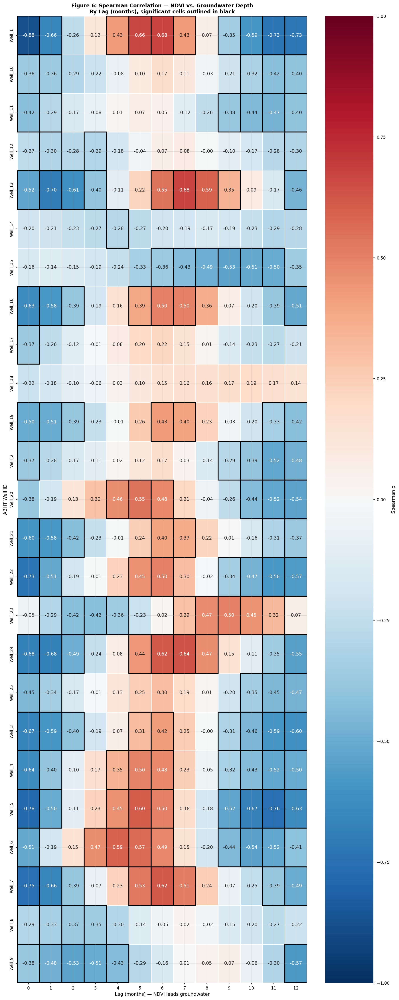

✅ Saved: Fig6_lagged_correlation.png


In [36]:
# ─── Figure 6: Lagged Correlation Heatmap ───
if not lag_corr_df.empty:
    pivot = lag_corr_df.pivot_table(index='well_id', columns='lag_months', values='spearman_rho')

    fig, ax = plt.subplots(figsize=(12, max(3, len(GW_WELLS) * 1.2)))
    sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
                vmin=-1, vmax=1, ax=ax, linewidths=0.5,
                cbar_kws={'label': "Spearman ρ"})

    # Mark significant cells
    for i, well_id in enumerate(pivot.index):
        for j, lag in enumerate(pivot.columns):
            row = lag_corr_df[(lag_corr_df['well_id'] == well_id) & (lag_corr_df['lag_months'] == lag)]
            if not row.empty and row['significant'].values[0]:
                ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=False, edgecolor='black', lw=2))

    ax.set_title('Figure 6: Spearman Correlation — NDVI vs. Groundwater Level\nBy Lag (months), significant cells outlined in black',
                 fontweight='bold')
    ax.set_xlabel('Lag (months) — NDVI leads groundwater')
    ax.set_ylabel('ABHT Well ID')
    plt.tight_layout()
    plt.savefig('Fig6_lagged_correlation.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✅ Saved: Fig6_lagged_correlation.png")

In [38]:
# ─── Figure: Precipitation-Corrected NDVI Residuals ───
if not corrected_df.empty:
    fig, axes = plt.subplots(len(HAF_SITES), 1, figsize=(10, 3.5 * len(HAF_SITES)), sharex=True)
    if len(HAF_SITES) == 1:
        axes = [axes]

    for ax, site in zip(axes, HAF_SITES):
        site_corr = corrected_df[corrected_df['site'] == site['name']].sort_values('date')
        ax.plot(site_corr['date'], site_corr['ndvi'],          color=COLORS['haf'],     linewidth=1.5, alpha=0.5, label='Raw NDVI')
        ax.plot(site_corr['date'], site_corr['ndvi_predicted'], color=COLORS['precip'],  linewidth=1.5, linestyle='--', label='Precip-Predicted NDVI')
        ax.plot(site_corr['date'], site_corr['ndvi_residual'],  color='black',           linewidth=2,   label='Residual (Corrected)')
        ax.axhline(0, color='gray', linewidth=0.8, linestyle=':')
        ax.set_ylabel('NDVI')
        ax.set_title(f"{site['name']} — Precipitation-Corrected NDVI", fontweight='bold')
        ax.legend(fontsize=8)

    fig.suptitle('Precipitation-Corrected NDVI: Isolating Planting Signal from Rainfall Variability',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('Fig_NDVI_precip_corrected.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✅ Saved: Fig_NDVI_precip_corrected.png")

Output hidden; open in https://colab.research.google.com to view.

In [39]:
# ─── Figure: Mann-Kendall Summary Table ───
fig, ax = plt.subplots(figsize=(12, max(4, len(mk_df) * 0.5)))
ax.axis('off')

display_cols = ['site', 'n_years', 'trend', 'p_value', 'sens_slope', 'tau', 'significant']
mk_display = mk_df[display_cols].copy()
mk_display.columns = ['Site', 'N Years', 'Trend', 'p-value', "Sen's Slope\n(NDVI/yr)", 'Tau', 'Significant']

table = ax.table(
    cellText=mk_display.values,
    colLabels=mk_display.columns,
    cellLoc='center', loc='center',
    bbox=[0, 0, 1, 1]
)
table.auto_set_font_size(False)
table.set_fontsize(9)

# Colour header
for j in range(len(mk_display.columns)):
    table[0, j].set_facecolor('#1F4E79')
    table[0, j].set_text_props(color='white', fontweight='bold')

# Colour significant rows
for i, row in enumerate(mk_df.itertuples(), 1):
    color = '#d4edda' if getattr(row, 'significant', False) == True else '#FFFFFF'
    for j in range(len(mk_display.columns)):
        table[i, j].set_facecolor(color)

ax.set_title('Mann-Kendall Trend Test Results — All Sites\n(Green = statistically significant trend, p < 0.05)',
             fontweight='bold', pad=15)
plt.savefig('Table_MannKendall.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Saved: Table_MannKendall.png")

Output hidden; open in https://colab.research.google.com to view.

In [40]:
# ─── Figure: SAR Soil Moisture Proxy ───
if not sar_df.empty:
    fig, axes = plt.subplots(len(HAF_SITES), 1, figsize=(10, 3.5 * len(HAF_SITES)), sharex=True)
    if len(HAF_SITES) == 1:
        axes = [axes]

    for ax, site in zip(axes, HAF_SITES):
        haf_sar  = sar_df[(sar_df['site'] == site['name'])   & (sar_df['type'] == 'HAF Planted')].sort_values('date')
        ctrl_sar = sar_df[(sar_df['site'] == CONTROL_SITES[HAF_SITES.index(site)]['name']) & (sar_df['type'] == 'Control')].sort_values('date')

        ax.plot(haf_sar['date'],  haf_sar['VH_VV_ratio'],  color=COLORS['haf'],    linewidth=2,   label='HAF Planted')
        ax.plot(ctrl_sar['date'], ctrl_sar['VH_VV_ratio'], color=COLORS['control'], linewidth=1.5, linestyle='--', alpha=0.8, label='Control')
        ax.set_ylabel('VH/VV Ratio (dB)\n(higher = wetter)')
        ax.set_title(f"{site['name']} — SAR Soil Moisture Proxy", fontweight='bold')
        ax.legend()

    fig.suptitle('Sentinel-1 SAR Soil Moisture Proxy (VH/VV ratio)\nHAF Planted vs. Control Sites',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('Fig_SAR_soil_moisture.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✅ Saved: Fig_SAR_soil_moisture.png")

Output hidden; open in https://colab.research.google.com to view.

In [41]:
# ─── Summary: All Outputs ───
print("\n" + "="*60)
print("📁 GENERATED OUTPUTS SUMMARY")
print("="*60)
outputs = [
    ("ndvi_df",       "Raw NDVI time series — all sites"),
    ("ndvi_gs",       "Growing season NDVI — filtered"),
    ("corrected_df",  "Precipitation-corrected NDVI residuals"),
    ("mk_df",         "Mann-Kendall trend test results"),
    ("evi_df",        "EVI time series"),
    ("lst_df",        "Land Surface Temperature"),
    ("sar_df",        "SAR soil moisture proxy"),
    ("gedi_df",       "GEDI canopy height"),
    ("pheno_df",      "Phenological metrics (SOS/EOS)"),
    ("lag_corr_df",   "Lagged NDVI-groundwater correlations"),
]
for var, desc in outputs:
    print(f"  ✅ {var:<20} — {desc}")

print("\n📊 FIGURES SAVED:")
figs = [
    "Fig2_NDVI_timeseries.png",
    "Fig3_NDVI_boxplot.png",
    "Fig5_groundwater_precip.png",
    "Fig6_lagged_correlation.png",
    "Fig_NDVI_precip_corrected.png",
    "Fig_SAR_soil_moisture.png",
    "Table_MannKendall.png",
]
for f in figs:
    print(f"  🖼️  {f}")
print("\n✅ All sections complete. Fill in site coordinates in Section 1 and run top to bottom.")


📁 GENERATED OUTPUTS SUMMARY
  ✅ ndvi_df              — Raw NDVI time series — all sites
  ✅ ndvi_gs              — Growing season NDVI — filtered
  ✅ corrected_df         — Precipitation-corrected NDVI residuals
  ✅ mk_df                — Mann-Kendall trend test results
  ✅ evi_df               — EVI time series
  ✅ lst_df               — Land Surface Temperature
  ✅ sar_df               — SAR soil moisture proxy
  ✅ gedi_df              — GEDI canopy height
  ✅ pheno_df             — Phenological metrics (SOS/EOS)
  ✅ lag_corr_df          — Lagged NDVI-groundwater correlations

📊 FIGURES SAVED:
  🖼️  Fig2_NDVI_timeseries.png
  🖼️  Fig3_NDVI_boxplot.png
  🖼️  Fig5_groundwater_precip.png
  🖼️  Fig6_lagged_correlation.png
  🖼️  Fig_NDVI_precip_corrected.png
  🖼️  Fig_SAR_soil_moisture.png
  🖼️  Table_MannKendall.png

✅ All sections complete. Fill in site coordinates in Section 1 and run top to bottom.


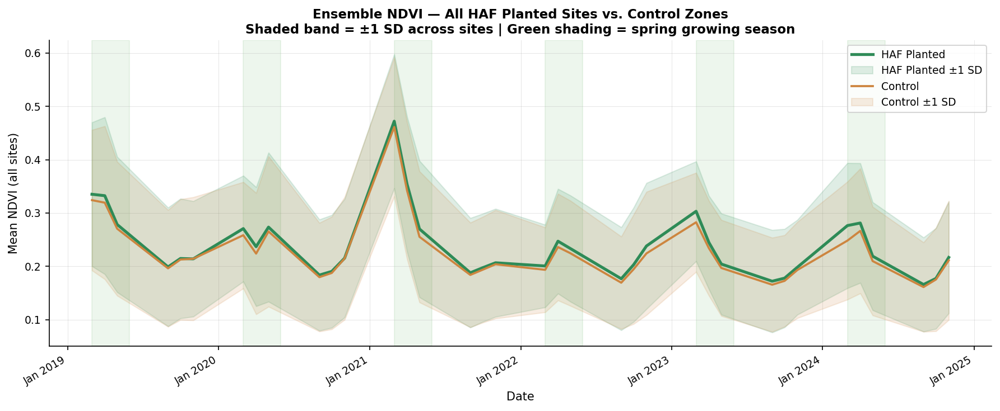

✅ Saved: FigA_ndvi_ensemble.png


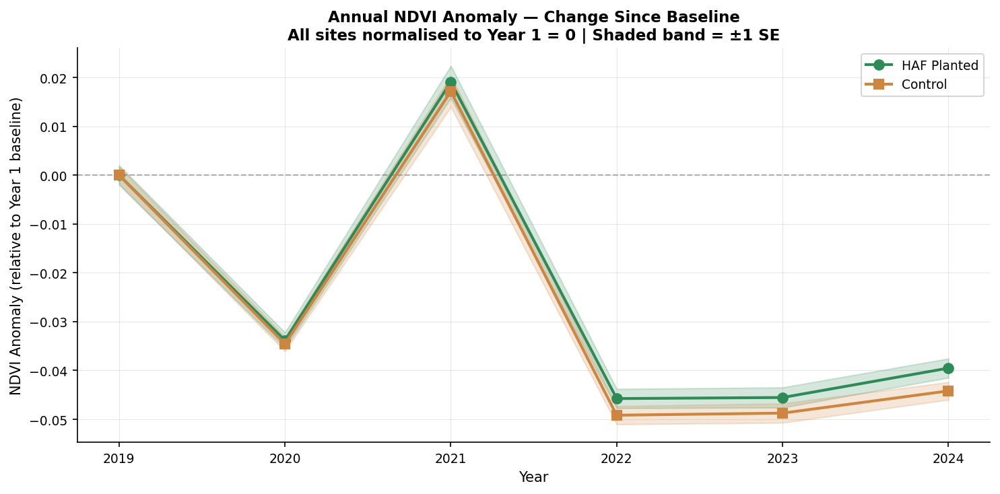

✅ Saved: FigB_ndvi_anomaly.png





✅ Saved: FigC_mk_lollipop.png


ValueError: Axis limits cannot be NaN or Inf

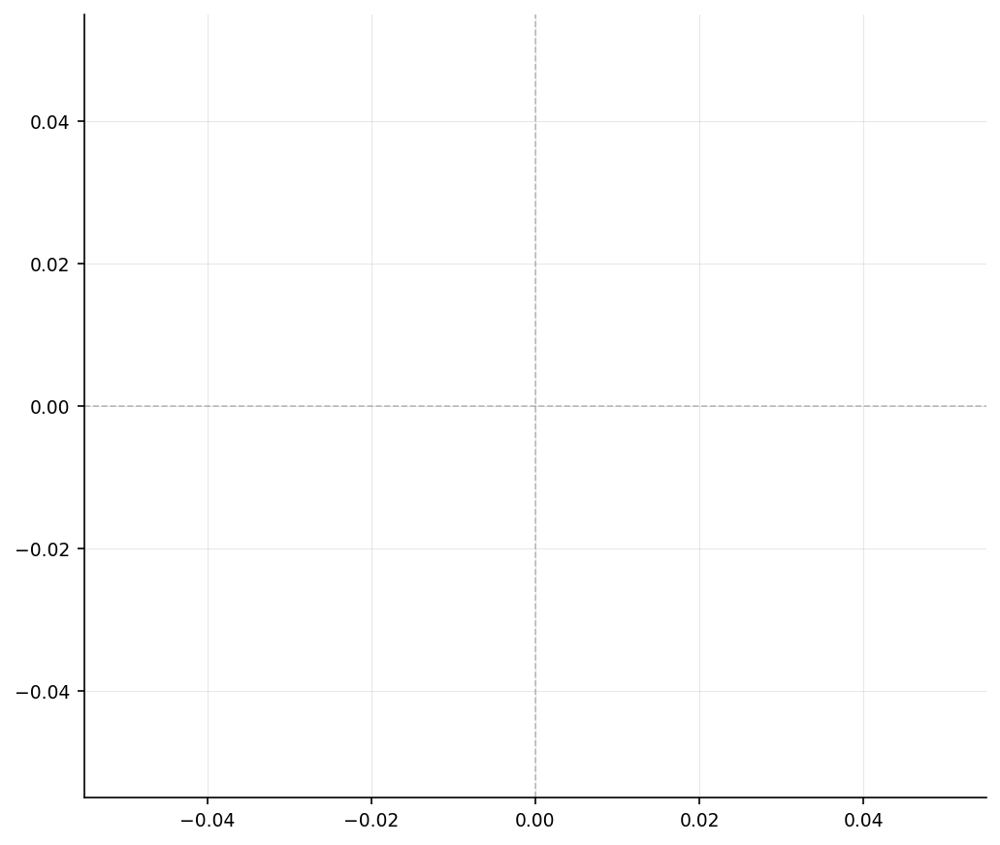

In [42]:
# ============================================================
#  SUMMARY FIGURES + SIGNIFICANCE MAP
#  Replaces per-farm plots with publication-quality aggregated
#  figures. Run after Sections 2-4 have completed.
# ============================================================

import folium
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import seaborn as sns
import numpy as np
import pandas as pd
from scipy import stats

plt.rcParams.update({
    'font.family':       'DejaVu Sans',
    'font.size':         10,
    'axes.titlesize':    11,
    'axes.labelsize':    10,
    'xtick.labelsize':   9,
    'ytick.labelsize':   9,
    'legend.fontsize':   9,
    'savefig.dpi':       300,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.grid':         True,
    'grid.alpha':        0.3,
})

COLORS = {
    'haf':       '#2E8B57',
    'control':   '#CD853F',
    'increase':  '#2E8B57',
    'decrease':  '#B22222',
    'no_trend':  '#AAAAAA',
    'insig':     '#CCCCCC',
}


# ============================================================
# FIGURE A — NDVI Ensemble Mean with Confidence Band
# One line per group (HAF planted / Control), shaded ±1 SD
# Much more readable than one panel per farm
# ============================================================

def plot_ndvi_ensemble(ndvi_df, growing_season_months=None):
    """
    Aggregates all farm NDVI into an ensemble mean ± 1 SD ribbon.
    Compares HAF planted vs control zones in one clean panel.
    """
    df = ndvi_df.copy()
    if growing_season_months:
        df = df[df['date'].dt.month.isin(growing_season_months)]

    # Monthly ensemble stats across all sites
    ensemble = (df.groupby(['date', 'type'])['ndvi']
                  .agg(['mean', 'std', 'count'])
                  .reset_index())
    ensemble.columns = ['date', 'type', 'mean', 'std', 'count']
    ensemble['se'] = ensemble['std'] / np.sqrt(ensemble['count'])

    fig, ax = plt.subplots(figsize=(12, 5))

    for stype, color, lw in [('HAF Planted', COLORS['haf'], 2.5),
                               ('Control',     COLORS['control'], 1.8)]:
        grp = ensemble[ensemble['type'] == stype].sort_values('date')
        ax.plot(grp['date'], grp['mean'], color=color, linewidth=lw,
                label=stype, zorder=3)
        ax.fill_between(grp['date'],
                        grp['mean'] - grp['std'],
                        grp['mean'] + grp['std'],
                        color=color, alpha=0.15, zorder=2, label=f'{stype} ±1 SD')

    # Shade growing seasons
    for yr in range(2019, 2025):
        ax.axvspan(pd.Timestamp(f'{yr}-03-01'), pd.Timestamp(f'{yr}-05-31'),
                   alpha=0.07, color='green', zorder=1)

    ax.set_xlabel('Date')
    ax.set_ylabel('Mean NDVI (all sites)')
    ax.set_title('Ensemble NDVI — All HAF Planted Sites vs. Control Zones\n'
                 'Shaded band = ±1 SD across sites | Green shading = spring growing season',
                 fontweight='bold')
    ax.legend(loc='upper right')
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b %Y'))
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig('FigA_ndvi_ensemble.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✅ Saved: FigA_ndvi_ensemble.png")


plot_ndvi_ensemble(ndvi_df, growing_season_months=GROWING_SEASON_MONTHS)


# ============================================================
# FIGURE B — NDVI Anomaly Relative to Year 1 Baseline
# Shows change from each site's own baseline — removes
# between-site differences so all sites are comparable
# ============================================================

def plot_ndvi_anomaly(ndvi_df, growing_season_months=None):
    """
    For each site, subtract its Year 1 mean NDVI.
    Then plot ensemble mean anomaly ± SE across all sites.
    This cancels out absolute NDVI differences between sites
    and focuses purely on change since planting.
    """
    df = ndvi_df.copy()
    if growing_season_months:
        df = df[df['date'].dt.month.isin(growing_season_months)]
    df['year'] = df['date'].dt.year

    # Compute Year 1 baseline mean per site
    baselines = (df[df['year'] == df['year'].min()]
                 .groupby(['site', 'type'])['ndvi']
                 .mean()
                 .rename('baseline'))
    df = df.merge(baselines.reset_index(), on=['site', 'type'], how='left')
    df['ndvi_anomaly'] = df['ndvi'] - df['baseline']

    # Annual ensemble
    annual = (df.groupby(['year', 'type'])['ndvi_anomaly']
                .agg(['mean', 'std', 'count'])
                .reset_index())
    annual['se'] = annual['std'] / np.sqrt(annual['count'])

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.axhline(0, color='gray', linewidth=1, linestyle='--', alpha=0.6)

    for stype, color, marker in [('HAF Planted', COLORS['haf'], 'o'),
                                   ('Control',     COLORS['control'], 's')]:
        grp = annual[annual['type'] == stype].sort_values('year')
        ax.plot(grp['year'], grp['mean'], color=color, linewidth=2,
                marker=marker, markersize=7, label=stype, zorder=3)
        ax.fill_between(grp['year'],
                        grp['mean'] - grp['se'],
                        grp['mean'] + grp['se'],
                        color=color, alpha=0.2, zorder=2)

    ax.set_xlabel('Year')
    ax.set_ylabel('NDVI Anomaly (relative to Year 1 baseline)')
    ax.set_title('Annual NDVI Anomaly — Change Since Baseline\n'
                 'All sites normalised to Year 1 = 0 | Shaded band = ±1 SE',
                 fontweight='bold')
    ax.legend()
    ax.xaxis.set_major_locator(plt.matplotlib.ticker.MaxNLocator(integer=True))
    plt.tight_layout()
    plt.savefig('FigB_ndvi_anomaly.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✅ Saved: FigB_ndvi_anomaly.png")


plot_ndvi_anomaly(ndvi_df, growing_season_months=GROWING_SEASON_MONTHS)


# ============================================================
# FIGURE C — Mann-Kendall Results Summary (Lollipop Chart)
# One dot per site, Sen's slope on x-axis, coloured by
# trend direction, sized by significance
# ============================================================

def plot_mk_lollipop(mk_df):
    """
    Lollipop chart: each farm is a horizontal line+dot.
    x = Sen's slope (NDVI/year), colour = trend direction,
    filled dot = significant (p<0.05), hollow = not significant.
    Far cleaner than a table when you have many sites.
    """
    # Filter to HAF Planted only (not controls or corrected)
    # Adjust the filter string if your site labels differ
    haf_mk = mk_df[~mk_df['site'].str.contains('Control|corrected', case=False, na=False)].copy()
    haf_mk = haf_mk.sort_values('sens_slope', ascending=True).reset_index(drop=True)

    colors = haf_mk.apply(
        lambda r: COLORS['increase'] if r['trend'] == 'increasing'
                  else (COLORS['decrease'] if r['trend'] == 'decreasing'
                        else COLORS['no_trend']),
        axis=1
    )

    fig, ax = plt.subplots(figsize=(8, max(6, len(haf_mk) * 0.35)))

    for i, (_, row) in enumerate(haf_mk.iterrows()):
        color = colors.iloc[i]
        ax.plot([0, row['sens_slope']], [i, i], color=color, linewidth=1.2, alpha=0.6)
        marker_kwargs = dict(color=color, zorder=5, s=60)
        if row.get('significant', False):
            ax.scatter(row['sens_slope'], i, marker='o', **marker_kwargs)
        else:
            ax.scatter(row['sens_slope'], i, marker='o',
                       facecolors='none', edgecolors=color, linewidth=1.5, zorder=5, s=60)

    ax.axvline(0, color='black', linewidth=1, linestyle='-', alpha=0.4)
    ax.set_yticks(range(len(haf_mk)))
    ax.set_yticklabels(haf_mk['site'], fontsize=8)
    ax.set_xlabel("Sen's Slope (NDVI units / year)")
    ax.set_title("Mann-Kendall Trend Test — Sen's Slope per Farm\n"
                 "Filled dot = significant (p<0.05) | Right of 0 = increasing NDVI",
                 fontweight='bold')

    # Legend
    legend_elements = [
        mpatches.Patch(facecolor=COLORS['increase'], label='Increasing'),
        mpatches.Patch(facecolor=COLORS['decrease'], label='Decreasing'),
        mpatches.Patch(facecolor=COLORS['no_trend'], label='No trend'),
        plt.scatter([], [], marker='o', color='gray', label='Significant (p<0.05)', s=60),
        plt.scatter([], [], marker='o', facecolors='none', edgecolors='gray',
                    label='Not significant', s=60, linewidths=1.5),
    ]
    ax.legend(handles=legend_elements, loc='lower right', fontsize=8)
    ax.grid(axis='x', alpha=0.3)
    ax.grid(axis='y', alpha=0.15)
    plt.tight_layout()
    plt.savefig('FigC_mk_lollipop.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✅ Saved: FigC_mk_lollipop.png")


plot_mk_lollipop(mk_df)


# ============================================================
# FIGURE D — Precipitation-Corrected vs Raw NDVI Trend
# Side-by-side Sen's slopes: raw vs residual
# Shows how much of the "decreasing" trend is just rainfall
# ============================================================

def plot_raw_vs_corrected_slopes(mk_df, corrected_df):
    """
    Scatter plot: raw Sen's slope (x) vs precip-corrected Sen's slope (y).
    Points above the diagonal = precip was suppressing the true trend.
    Points below = precip was inflating the trend.
    """
    # Get annual means of corrected residuals and run MK on them
    corr_mk_rows = []
    for site_name in corrected_df['site'].unique():
        site_data = corrected_df[corrected_df['site'] == site_name].sort_values('date')
        annual = site_data.groupby(site_data['date'].dt.year)['ndvi_residual'].mean().dropna()
        if len(annual) < 4:
            continue
        result = mk.original_test(annual.values)
        corr_mk_rows.append({
            'site':             site_name,
            'slope_corrected':  result.slope,
            'trend_corrected':  result.trend,
            'p_corrected':      result.p,
            'sig_corrected':    result.p < 0.05
        })
    corr_mk = pd.DataFrame(corr_mk_rows)

    # Merge with raw mk_df
    haf_mk = mk_df[~mk_df['site'].str.contains('Control|corrected', case=False, na=False)].copy()
    merged = haf_mk.merge(corr_mk, on='site', how='inner')

    fig, ax = plt.subplots(figsize=(8, 7))

    # Quadrant reference lines
    ax.axhline(0, color='gray', linewidth=0.8, linestyle='--', alpha=0.5)
    ax.axvline(0, color='gray', linewidth=0.8, linestyle='--', alpha=0.5)

    # Diagonal (no change line)
    lim = max(abs(merged['sens_slope'].max()), abs(merged['sens_slope'].min()),
              abs(merged['slope_corrected'].max()), abs(merged['slope_corrected'].min())) * 1.1
    ax.plot([-lim, lim], [-lim, lim], color='black', linewidth=1, linestyle=':', alpha=0.4, label='No change (y=x)')

    # Points
    for _, row in merged.iterrows():
        color = (COLORS['increase'] if row['trend'] == 'increasing'
                 else COLORS['decrease'] if row['trend'] == 'decreasing'
                 else COLORS['no_trend'])
        ax.scatter(row['sens_slope'], row['slope_corrected'],
                   color=color, s=70,
                   marker='o' if row['significant'] else 's',
                   edgecolors='white', linewidth=0.5, zorder=4, alpha=0.85)

    # Quadrant labels
    offset = lim * 0.05
    ax.text( lim - offset,  lim - offset, 'Both increasing', ha='right', va='top',   fontsize=8, color='gray')
    ax.text(-lim + offset,  lim - offset, 'Rain-masked\nreal increase', ha='left', va='top',  fontsize=8, color='gray')
    ax.text( lim - offset, -lim + offset, 'Rain-inflated\ndecrease',  ha='right', va='bottom', fontsize=8, color='gray')
    ax.text(-lim + offset, -lim + offset, 'Both decreasing', ha='left',  va='bottom', fontsize=8, color='gray')

    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_xlabel("Raw Sen's Slope (NDVI / year)")
    ax.set_ylabel("Precipitation-Corrected Sen's Slope (NDVI residual / year)")
    ax.set_title("Raw vs. Precipitation-Corrected NDVI Trends\n"
                 "Points above y=x line: rainfall was masking a real vegetation signal",
                 fontweight='bold')

    legend_elements = [
        mpatches.Patch(facecolor=COLORS['increase'], label='Raw trend: increasing'),
        mpatches.Patch(facecolor=COLORS['decrease'], label='Raw trend: decreasing'),
        plt.scatter([], [], marker='o', color='gray', s=70, label='Significant (p<0.05)'),
        plt.scatter([], [], marker='s', color='gray', s=70, label='Not significant'),
    ]
    ax.legend(handles=legend_elements, fontsize=8)
    plt.tight_layout()
    plt.savefig('FigD_raw_vs_corrected.png', dpi=300, bbox_inches='tight')
    plt.show()
    print("✅ Saved: FigD_raw_vs_corrected.png")


plot_raw_vs_corrected_slopes(mk_df, corrected_df)


# ============================================================
# FIGURE E — Interactive Folium Map: Farm Significance
# Colour-coded by MK trend direction + significance
# Popup shows farm ID, trend, p-value, Sen's slope
# ============================================================

def make_significance_map(mk_df, haf_sites):
    """
    Interactive HTML map with one circle per farm:
      Green  = significant increasing NDVI trend
      Red    = significant decreasing NDVI trend
      Orange = non-significant increasing
      Grey   = non-significant / no trend
    Click any circle for farm details.
    """
    haf_mk = mk_df[~mk_df['site'].str.contains('Control|corrected', case=False, na=False)].copy()

    # Centre map on mean of all farms
    mean_lat = np.mean([s['lat'] for s in haf_sites])
    mean_lon = np.mean([s['lon'] for s in haf_sites])

    m = folium.Map(location=[mean_lat, mean_lon], zoom_start=10,
                   tiles='CartoDB positron')

    # Colour logic
    def get_color(row):
        if row.get('significant', False):
            return '#2E8B57' if row['trend'] == 'increasing' else '#B22222'
        else:
            return '#FF8C00' if row['trend'] == 'increasing' else '#AAAAAA'

    def get_radius(row):
        # Size by absolute Sen's slope — more change = bigger circle
        slope = abs(row.get('sens_slope', 0) or 0)
        return max(6, min(20, slope * 5000))

    # Add farm circles
    for site in haf_sites:
        site_id = str(site['name'])
        mk_row  = haf_mk[haf_mk['site'] == site_id]

        if mk_row.empty:
            color  = '#CCCCCC'
            radius = 6
            popup_text = f"<b>{site_id}</b><br>No trend data"
        else:
            row    = mk_row.iloc[0]
            color  = get_color(row)
            radius = get_radius(row)
            sig_label = "✅ Significant" if row.get('significant', False) else "⬜ Not significant"
            popup_text = (
                f"<b>Farm: {site_id}</b><br>"
                f"Trend: <b>{row['trend']}</b><br>"
                f"p-value: {row['p_value']:.4f}<br>"
                f"Sen's slope: {row['sens_slope']:.5f} NDVI/yr<br>"
                f"Tau: {row['tau']:.3f}<br>"
                f"{sig_label}<br>"
                f"Planted: {site.get('planted_year', 'N/A')}<br>"
                f"Species: {site.get('species', 'N/A')}"
            )

        folium.CircleMarker(
            location=[site['lat'], site['lon']],
            radius=radius,
            color='white',
            weight=1,
            fill=True,
            fill_color=color,
            fill_opacity=0.85,
            popup=folium.Popup(popup_text, max_width=260),
            tooltip=f"{site_id} — {mk_row.iloc[0]['trend'] if not mk_row.empty else 'no data'}"
        ).add_to(m)

    # Legend HTML
    legend_html = """
    <div style="position: fixed; bottom: 40px; left: 40px; z-index: 1000;
                background: white; padding: 12px 16px; border-radius: 8px;
                border: 1px solid #ccc; font-size: 13px; line-height: 1.8;">
      <b>NDVI Trend (Mann-Kendall)</b><br>
      <span style="color:#2E8B57">●</span> Significant increase (p&lt;0.05)<br>
      <span style="color:#B22222">●</span> Significant decrease (p&lt;0.05)<br>
      <span style="color:#FF8C00">●</span> Non-significant increase<br>
      <span style="color:#AAAAAA">●</span> Non-significant / no trend<br>
      <i style="font-size:11px">Circle size = |Sen's slope|</i>
    </div>
    """
    m.get_root().html.add_child(folium.Element(legend_html))

    output_path = 'farm_significance_map.html'
    m.save(output_path)
    print(f"✅ Saved interactive map: {output_path}")
    print("   Open in browser or from Colab with:")
    print("   from IPython.display import IFrame; IFrame('farm_significance_map.html', width=900, height=600)")
    return m


significance_map = make_significance_map(mk_df, HAF_SITES)

# Display inline in Colab
from IPython.display import IFrame
IFrame('farm_significance_map.html', width='100%', height=600)